In [ ]:
import pandas as pd

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df[df["TotalCharges"].isnull()][["customerID", "tenure", "TotalCharges"]]

,customerID,tenure,TotalCharges


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [ ]:
df = df.drop(columns=["customerID"])

In [ ]:
df["Churn"].value_counts()
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.463013
Yes,26.536987


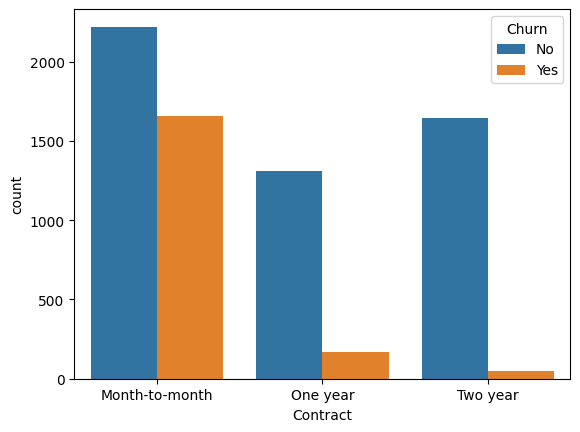

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="Contract", hue="Churn")
plt.show()

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])

print("df:", df["TotalCharges"].dtype)
print("X:", X["TotalCharges"].dtype)
print("missing in TotalCharges:", df["TotalCharges"].isna().sum())

df: float64
X: float64
missing in TotalCharges: 0


In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [ ]:
print(X_train["TotalCharges"].dtype)
print(num_cols)
print(len(preprocessor.fit(X_train).get_feature_names_out()))

float64
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
45


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

baseline = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])
baseline.fit(X_train, y_train)

pred = baseline.predict(X_test)
proba = baseline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8421349040274871


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
ratio = neg / pos  # about 2.8, used to handle imbalance

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                             eval_metric="logloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                               random_state=42, verbose=-1),
}

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "recall", "precision", "f1"])
    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "F1": scores["test_f1"].mean(),
    })

results_df = pd.DataFrame(results).round(3)
print(results_df)

                 Model  ROC-AUC  Recall  Precision     F1
0  Logistic Regression    0.846   0.543      0.653  0.592
1        Random Forest    0.820   0.480      0.626  0.543
2              XGBoost    0.845   0.515      0.649  0.574
3             LightGBM    0.841   0.521      0.651  0.579


In [ ]:
models_weighted = {
    "Logistic (weighted)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest (weighted)": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                       random_state=42, n_jobs=-1),
    "XGBoost (weighted)": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                        scale_pos_weight=ratio, eval_metric="logloss", random_state=42),
    "LightGBM (weighted)": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                                          class_weight="balanced", random_state=42, verbose=-1),
}

In [ ]:
results_weighted = []

for name, model in models_weighted.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=["roc_auc", "recall", "precision", "f1"])
    results_weighted.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Recall": scores["test_recall"].mean(),
        "Precision": scores["test_precision"].mean(),
        "F1": scores["test_f1"].mean(),
    })

results_weighted_df = pd.DataFrame(results_weighted).round(3)
print(results_weighted_df)

                      Model  ROC-AUC  Recall  Precision     F1
0       Logistic (weighted)    0.846   0.801      0.517  0.628
1  Random Forest (weighted)    0.820   0.473      0.629  0.539
2        XGBoost (weighted)    0.844   0.773      0.533  0.631
3       LightGBM (weighted)    0.843   0.761      0.539  0.631


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1)),
])

param_dist = {
    "model__n_estimators": randint(100, 500),
    "model__learning_rate": uniform(0.01, 0.1),
    "model__num_leaves": randint(8, 40),
    "model__min_child_samples": randint(10, 60),
    "model__subsample": uniform(0.6, 0.4),
    "model__subsample_freq": [1],
    "model__colsample_bytree": uniform(0.6, 0.4),
    "model__reg_lambda": uniform(0, 5),
}

search = RandomizedSearchCV(pipe, param_dist, n_iter=30, scoring="roc_auc",
                            cv=cv, random_state=42, n_jobs=2)
search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(search.best_score_, 3))
print(search.best_params_)

Best CV ROC-AUC: 0.848
{'model__colsample_bytree': np.float64(0.8253152871382157), 'model__learning_rate': np.float64(0.04854165025399162), 'model__min_child_samples': 35, 'model__n_estimators': 152, 'model__num_leaves': 9, 'model__reg_lambda': np.float64(3.4211651325607844), 'model__subsample': np.float64(0.7760609974958406), 'model__subsample_freq': 1}


In [ ]:
from sklearn.model_selection import cross_val_predict

best_model = search.best_estimator_
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv,
                              method="predict_proba")[:, 1]

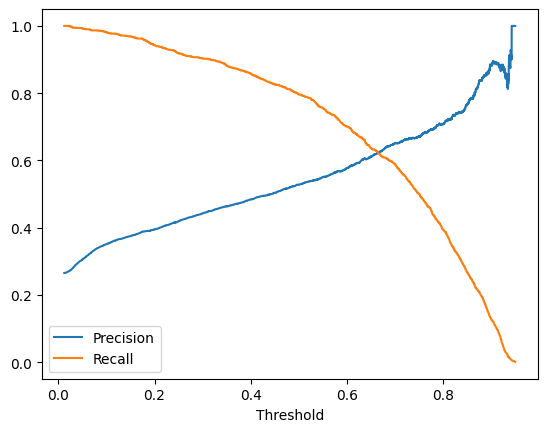

In [ ]:
from sklearn.metrics import precision_recall_curve
import numpy as np

prec, rec, thr = precision_recall_curve(y_train, oof_proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Threshold")
plt.legend()
plt.show()

In [ ]:
f2 = (5 * prec[:-1] * rec[:-1]) / (4 * prec[:-1] + rec[:-1] + 1e-9)
best_idx = np.argmax(f2)
best_thr = thr[best_idx]

print("Chosen threshold:", round(best_thr, 3))
print("Precision:", round(prec[:-1][best_idx], 3),
      "Recall:", round(rec[:-1][best_idx], 3))

Chosen threshold: 0.326
Precision: 0.454 Recall: 0.898


Number of features: 45


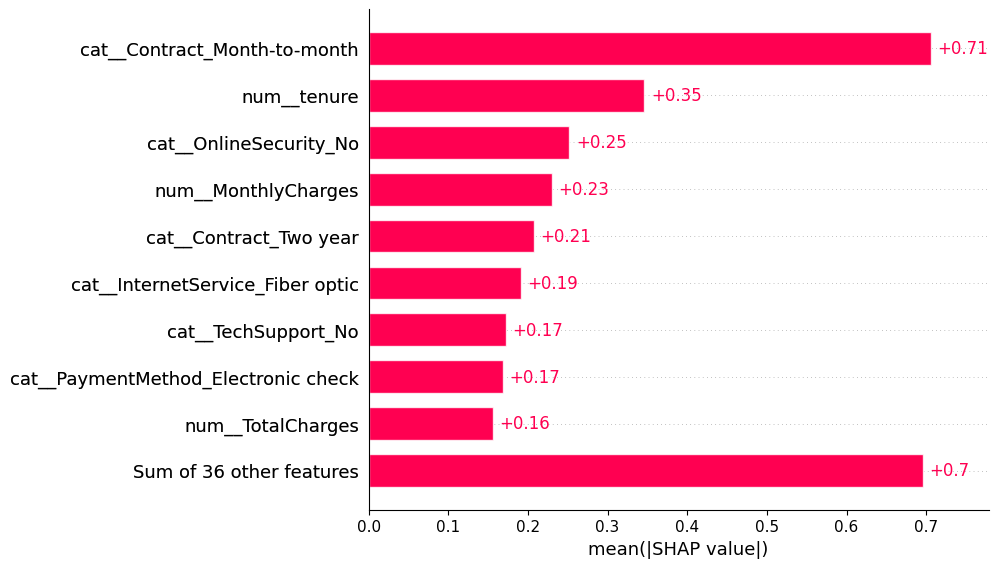

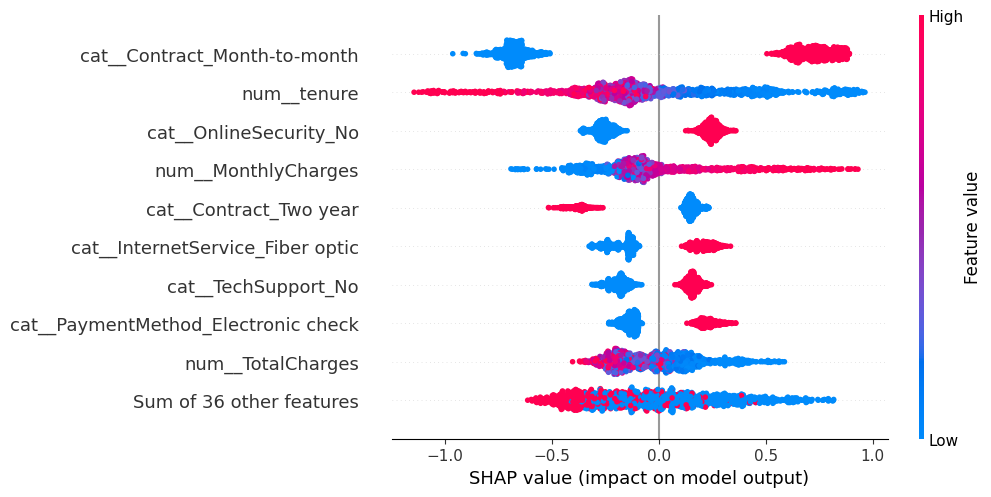

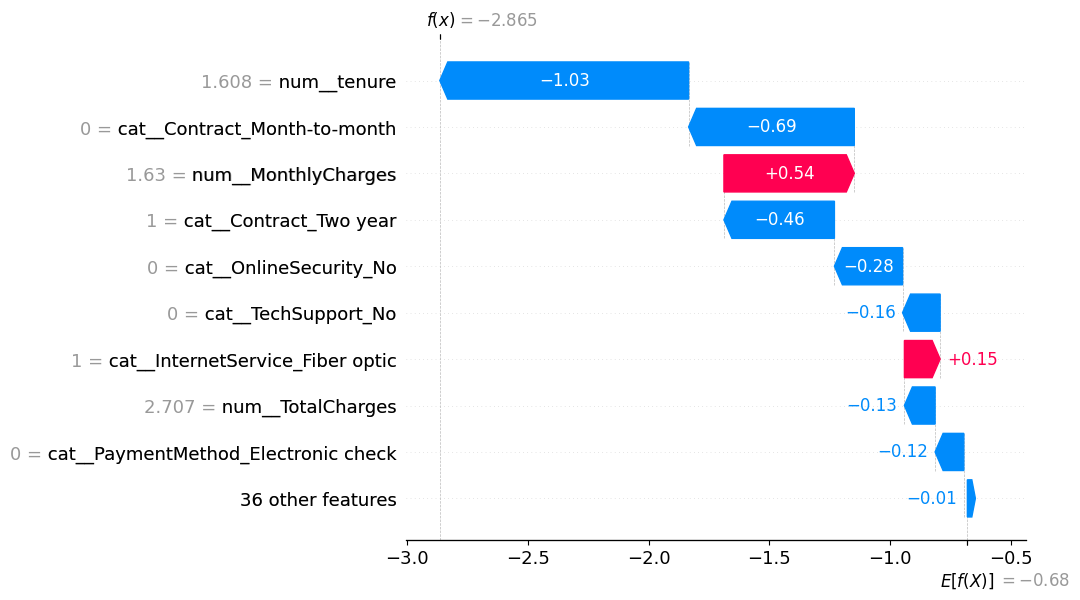

In [ ]:
import shap
import matplotlib.pyplot as plt
import pandas as pd

prep = search.best_estimator_.named_steps["prep"]
model = search.best_estimator_.named_steps["model"]

X_test_t = prep.transform(X_test)
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()

feature_names = prep.get_feature_names_out()
X_test_df = pd.DataFrame(X_test_t, columns=feature_names)
print("Number of features:", len(feature_names))   # should be 45

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_df)

# Some shap versions return values for both classes; keep the churn class
if len(shap_values.values.shape) == 3:
    shap_values = shap_values[:, :, 1]

shap.plots.bar(shap_values, max_display=10, show=False)
plt.savefig("shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.savefig("shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

shap.plots.waterfall(shap_values[0])

In [ ]:
print(X_train["TotalCharges"].dtype)
print(len(preprocessor.fit(X_train).get_feature_names_out()))

float64
45


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

test_proba = search.best_estimator_.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_thr).astype(int)

print("Threshold used:", round(best_thr, 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print("Precision:", round(precision_score(y_test, test_pred), 3))
print("Recall:", round(recall_score(y_test, test_pred), 3))
print("F1:", round(f1_score(y_test, test_pred), 3))
print(confusion_matrix(y_test, test_pred))

default_pred = (test_proba >= 0.5).astype(int)
print("Precision @0.5:", round(precision_score(y_test, default_pred), 3))
print("Recall @0.5:", round(recall_score(y_test, default_pred), 3))

Threshold used: 0.326
ROC-AUC: 0.849
Precision: 0.452
Recall: 0.901
F1: 0.602
[[626 409]
 [ 37 337]]
Precision @0.5: 0.523
Recall @0.5: 0.802


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [ ]:
import numpy as np
import pandas as pd

# Assumptions (illustrative, not real company data)
offer_cost = 20        # cost of one retention offer
success_rate = 0.30    # share of contacted churners who accept and stay
months_kept = 12       # months of revenue kept if the customer stays

monthly = X_test["MonthlyCharges"].values
y_true = y_test.values

def business_value(pred, name):
    contacted = pred == 1
    caught = contacted & (y_true == 1)
    cost = contacted.sum() * offer_cost
    saved = (monthly[caught] * months_kept * success_rate).sum()
    return {"Strategy": name,
            "Contacted": int(contacted.sum()),
            "Churners caught": int(caught.sum()),
            "Offer cost": round(cost),
            "Revenue saved": round(saved),
            "Net benefit": round(saved - cost)}

strategies = [
    business_value(np.zeros(len(y_true), dtype=int), "Contact nobody"),
    business_value(np.ones(len(y_true), dtype=int), "Contact everyone"),
    business_value((test_proba >= 0.5).astype(int), "Model, threshold 0.5"),
    business_value((test_proba >= best_thr).astype(int), "Model, tuned threshold"),
]
print(pd.DataFrame(strategies).to_string(index=False))

              Strategy  Contacted  Churners caught  Offer cost  Revenue saved  Net benefit
        Contact nobody          0                0           0              0            0
      Contact everyone       1409              374       28180          97974        69794
  Model, threshold 0.5        574              300       11480          80272        68792
Model, tuned threshold        746              337       14920          90120        75200


In [ ]:
import joblib, json, sklearn, lightgbm

joblib.dump(search.best_estimator_, "churn_model.joblib")
json.dump({"threshold": float(best_thr)}, open("threshold.json", "w"))
print(sklearn.__version__, lightgbm.__version__)

1.6.1 4.6.0
